### EDA

In [3]:
# Step 1: Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the cleaned dataset path
data_path = Path("../data/processed/transactions_cleaned.csv")

# Check whether the dataset exists
print("Dataset exists:", data_path.exists())

# Read only the first 1,000 rows for initial inspection
df = pd.read_csv(data_path, nrows=1000)

# Display basic information
print("Sample shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 transactions:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset exists: True
Sample shape: (1000, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

First 5 transactions:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            1000 non-null   int64  
 1   type            1000 non-null   str    
 2   amount          1000 non-null   float64
 3   nameOrig        1000 non-null   str    
 4   oldbalanceOrg   1000 non-null   float64
 5   newbalanceOrig  1000 non-null   float64
 6   nameDest        1000 non-null   str    
 7   oldbalanceDest  1000 non-null   float64
 8   newbalanceDest  1000 non-null   float64
 9   isFraud         1000 non-null   int64  
 10  isFlaggedFraud  1000 non-null   int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 86.1 KB


Total transactions: 6362620

Transactions by type:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
dtype: int64

Legitimate (0) and fraud (1) counts:
isFraud
0    6354407
1       8213
dtype: int64

Fraud transactions by type:
type
CASH_OUT    4116
TRANSFER    4097
CASH_IN        0
DEBIT          0
PAYMENT        0
Name: 1, dtype: int64


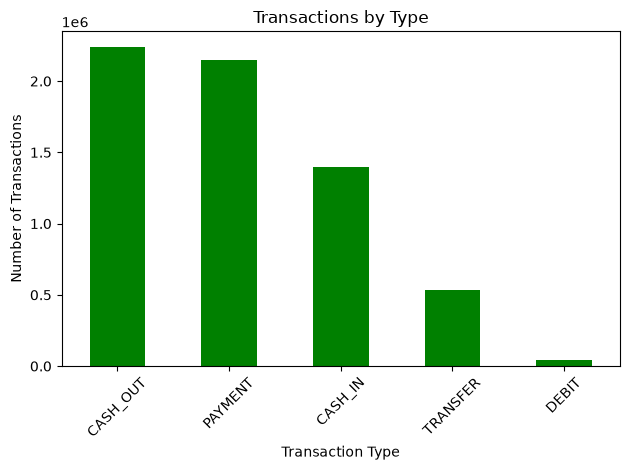

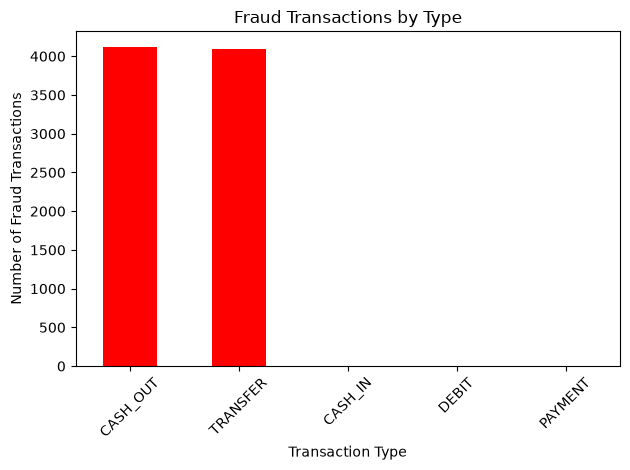

In [6]:
# Step 2: Analyze transaction types and fraud counts

import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/processed/transactions_cleaned.csv"

type_counts = pd.Series(dtype="int64")
fraud_counts = pd.Series(dtype="int64")
fraud_by_type = pd.DataFrame()

total_rows = 0

# Read the full dataset in chunks
for chunk in pd.read_csv(
    data_path,
    usecols=["type", "isFraud"],
    chunksize=500_000
):
    total_rows += len(chunk)

    # Count each transaction type
    type_counts = type_counts.add(
        chunk["type"].value_counts(),
        fill_value=0
    )

    # Count legitimate and fraudulent transactions
    fraud_counts = fraud_counts.add(
        chunk["isFraud"].value_counts(),
        fill_value=0
    )

    # Count fraud and legitimate transactions by type
    grouped = chunk.groupby(
        ["type", "isFraud"]
    ).size().unstack(fill_value=0)

    fraud_by_type = fraud_by_type.add(
        grouped,
        fill_value=0
    )

# Display results
type_counts = type_counts.astype(int).sort_values(ascending=False)
fraud_counts = fraud_counts.astype(int)

print("Total transactions:", total_rows)

print("\nTransactions by type:")
print(type_counts)

print("\nLegitimate (0) and fraud (1) counts:")
print(fraud_counts)

print("\nFraud transactions by type:")
print(fraud_by_type[1].fillna(0).astype(int).sort_values(ascending=False))

# Chart 1: Transaction type distribution
type_counts.plot(kind="bar",color="green")
plt.title("Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: Fraud counts by transaction type
fraud_by_type[1].fillna(0).sort_values(ascending=False).plot(kind="bar",color="red")
plt.title("Fraud Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

          Total Transactions  Fraud Transactions  Fraud Rate (%)
type                                                            
TRANSFER              532909              4097.0          0.7688
CASH_OUT             2237500              4116.0          0.1840
CASH_IN              1399284                 0.0          0.0000
DEBIT                  41432                 0.0          0.0000
PAYMENT              2151495                 0.0          0.0000


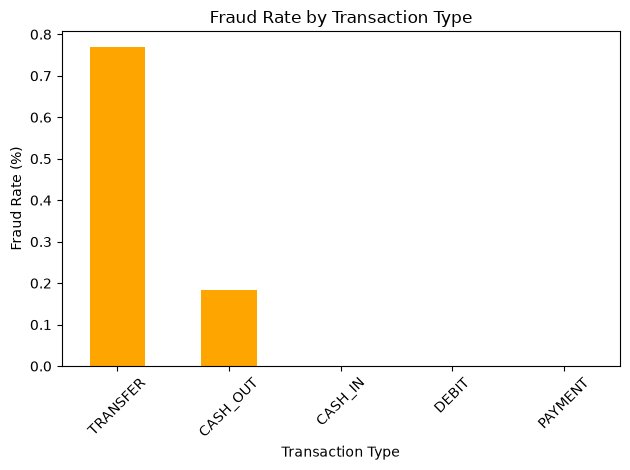

In [7]:
# Step 3: Fraud rate by transaction type

fraud_by_type_counts = fraud_by_type[1].fillna(0)

fraud_rate = (fraud_by_type_counts / type_counts) * 100

fraud_summary = pd.DataFrame({
    "Total Transactions": type_counts,
    "Fraud Transactions": fraud_by_type_counts,
    "Fraud Rate (%)": fraud_rate
})

fraud_summary = fraud_summary.sort_values(
    by="Fraud Rate (%)",
    ascending=False
)

print(fraud_summary.round(4))

# Plot fraud rate
fraud_summary["Fraud Rate (%)"].plot(kind="bar",color="orange")
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Transaction Class  Number of Transactions  Average Amount  Maximum Amount
       Legitimate                 6354407       178197.04     92445516.64
            Fraud                    8213      1467967.30     10000000.00


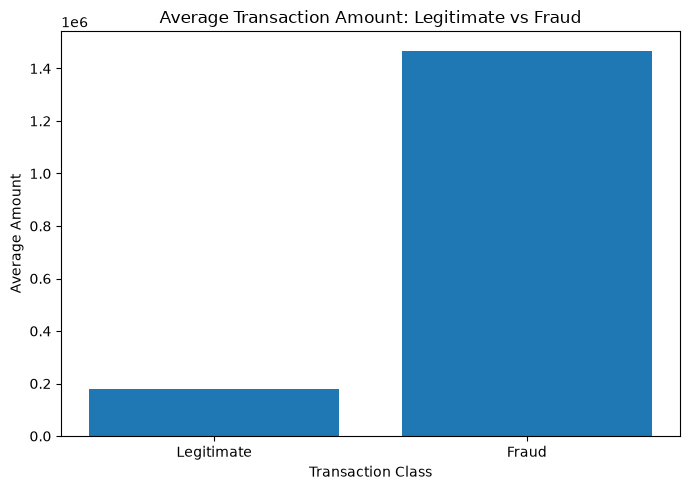

In [10]:
# Step 4: Analyze transaction amounts

import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/processed/transactions_cleaned.csv"

amount_stats = {
    0: {"count": 0, "total": 0.0, "max": 0.0},
    1: {"count": 0, "total": 0.0, "max": 0.0}
}

# Read the dataset in chunks
for chunk in pd.read_csv(
    data_path,
    usecols=["amount", "isFraud"],
    chunksize=500_000
):
    for label in [0, 1]:
        amounts = chunk.loc[
            chunk["isFraud"] == label, "amount"
        ]

        amount_stats[label]["count"] += len(amounts)
        amount_stats[label]["total"] += amounts.sum()

        if len(amounts) > 0:
            amount_stats[label]["max"] = max(
                amount_stats[label]["max"],
                amounts.max()
            )

# Create summary table
amount_summary = pd.DataFrame({
    "Transaction Class": ["Legitimate", "Fraud"],
    "Number of Transactions": [
        amount_stats[0]["count"],
        amount_stats[1]["count"]
    ],
    "Average Amount": [
        amount_stats[0]["total"] / amount_stats[0]["count"],
        amount_stats[1]["total"] / amount_stats[1]["count"]
    ],
    "Maximum Amount": [
        amount_stats[0]["max"],
        amount_stats[1]["max"]
    ]
})

print(amount_summary.round(2).to_string(index=False))

# Fix: Plot average transaction amounts

plt.figure(figsize=(7, 5))

plt.bar(
    amount_summary["Transaction Class"],
    amount_summary["Average Amount"]
)

plt.title("Average Transaction Amount: Legitimate vs Fraud")
plt.xlabel("Transaction Class")
plt.ylabel("Average Amount")
plt.tight_layout()
plt.show()

Sampled transactions: 254505

Transaction amount summary:
                      Median         Q1          Q3
Transaction Class                                  
Fraud              444898.97  112363.33  1698263.69
Legitimate          74659.83   13322.60   208694.08


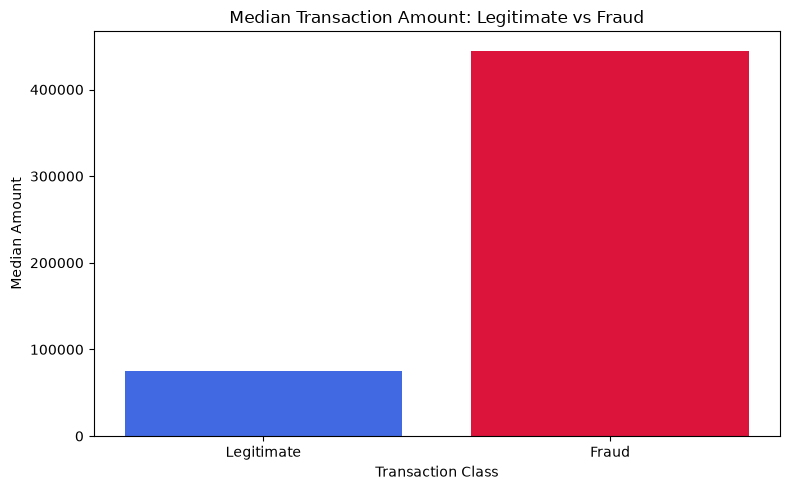

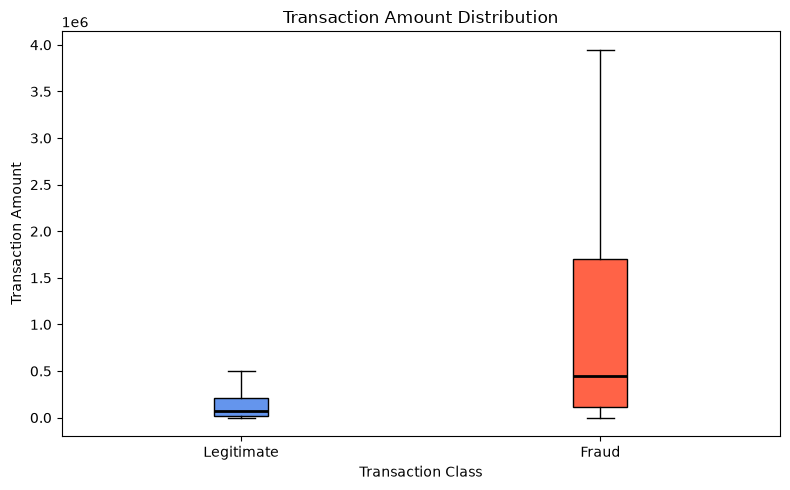

In [11]:
# Step 5: Multicolor transaction amount analysis

import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/processed/transactions_cleaned.csv"

# Read a sample from each chunk
sample_chunks = []

for i, chunk in enumerate(
    pd.read_csv(
        data_path,
        usecols=["amount", "isFraud"],
        chunksize=500_000
    )
):
    sample = chunk.sample(frac=0.04, random_state=42 + i)
    sample_chunks.append(sample)

# Combine samples
sample_df = pd.concat(sample_chunks, ignore_index=True)

# Add readable class names
sample_df["Transaction Class"] = sample_df["isFraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

# Calculate median and quartiles
amount_summary = sample_df.groupby("Transaction Class")["amount"].agg(
    Median="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

print("Sampled transactions:", len(sample_df))
print("\nTransaction amount summary:")
print(amount_summary.round(2))

# Plot 1: Multicolor median amount comparison
classes = ["Legitimate", "Fraud"]
medians = amount_summary.loc[classes, "Median"]

plt.figure(figsize=(8, 5))
plt.bar(
    classes,
    medians,
    color=["royalblue", "crimson"]
)
plt.title("Median Transaction Amount: Legitimate vs Fraud")
plt.xlabel("Transaction Class")
plt.ylabel("Median Amount")
plt.tight_layout()
plt.show()

# Plot 2: Multicolor boxplot
legitimate_amounts = sample_df.loc[
    sample_df["isFraud"] == 0, "amount"
]

fraud_amounts = sample_df.loc[
    sample_df["isFraud"] == 1, "amount"
]

plt.figure(figsize=(8, 5))

box = plt.boxplot(
    [legitimate_amounts, fraud_amounts],
    tick_labels=["Legitimate", "Fraud"],
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 2}
)

box_colors = ["cornflowerblue", "tomato"]

for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Class")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

Median balance changes:
            origin_balance_change  destination_balance_change
isFraud                                                      
Legitimate                   0.00                        0.00
Fraud                   444898.97                    12855.05


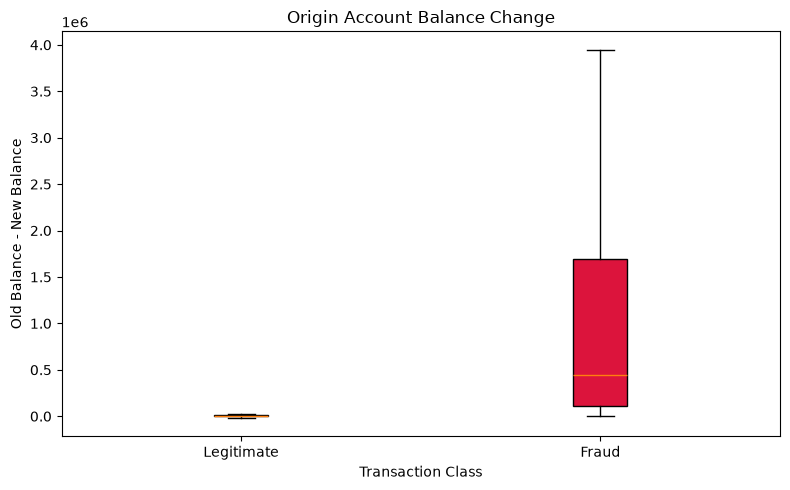

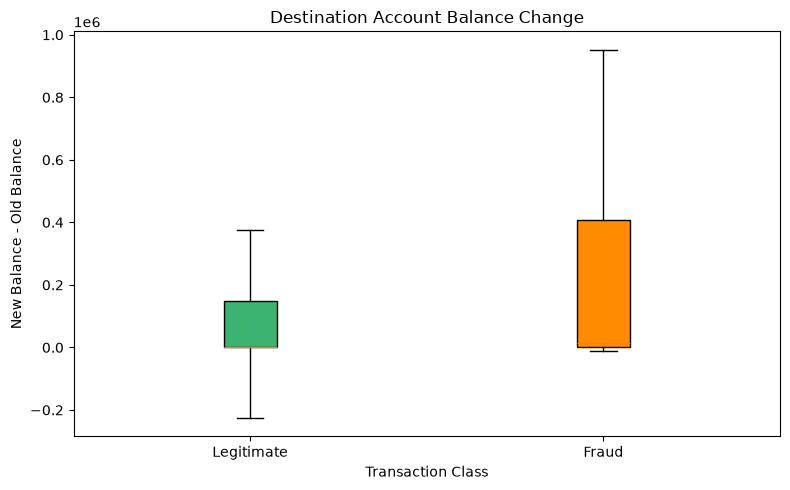

In [12]:
# Step 6: Analyze account balance changes

import pandas as pd
import matplotlib.pyplot as plt

data_path = "../data/processed/transactions_cleaned.csv"

sample_chunks = []

# Read a sample from the full dataset
for i, chunk in enumerate(
    pd.read_csv(
        data_path,
        usecols=[
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest",
            "isFraud"
        ],
        chunksize=500_000
    )
):
    sample = chunk.sample(
        frac=0.04,
        random_state=42 + i
    )
    sample_chunks.append(sample)

sample_df = pd.concat(sample_chunks, ignore_index=True)

# Calculate balance changes
sample_df["origin_balance_change"] = (
    sample_df["oldbalanceOrg"] - sample_df["newbalanceOrig"]
)

sample_df["destination_balance_change"] = (
    sample_df["newbalanceDest"] - sample_df["oldbalanceDest"]
)

# Display median balance changes by transaction class
balance_summary = sample_df.groupby("isFraud")[
    ["origin_balance_change", "destination_balance_change"]
].median()

balance_summary.index = balance_summary.index.map({
    0: "Legitimate",
    1: "Fraud"
})

print("Median balance changes:")
print(balance_summary.round(2))

# Plot 1: Origin balance change
plt.figure(figsize=(8, 5))

box = plt.boxplot(
    [
        sample_df.loc[
            sample_df["isFraud"] == 0, "origin_balance_change"
        ],
        sample_df.loc[
            sample_df["isFraud"] == 1, "origin_balance_change"
        ]
    ],
    tick_labels=["Legitimate", "Fraud"],
    patch_artist=True,
    showfliers=False
)

for patch, color in zip(box["boxes"], ["royalblue", "crimson"]):
    patch.set_facecolor(color)

plt.title("Origin Account Balance Change")
plt.xlabel("Transaction Class")
plt.ylabel("Old Balance - New Balance")
plt.tight_layout()
plt.show()

# Plot 2: Destination balance change
plt.figure(figsize=(8, 5))

box = plt.boxplot(
    [
        sample_df.loc[
            sample_df["isFraud"] == 0, "destination_balance_change"
        ],
        sample_df.loc[
            sample_df["isFraud"] == 1, "destination_balance_change"
        ]
    ],
    tick_labels=["Legitimate", "Fraud"],
    patch_artist=True,
    showfliers=False
)

for patch, color in zip(box["boxes"], ["mediumseagreen", "darkorange"]):
    patch.set_facecolor(color)

plt.title("Destination Account Balance Change")
plt.xlabel("Transaction Class")
plt.ylabel("New Balance - Old Balance")
plt.tight_layout()
plt.show()